In [26]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib
# matplotlib.use('agg')
import matplotlib.pyplot as plt
# 【关键两行】——必须同时设置！
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'PingFang SC', 'Heiti TC', 'WenQuanYi Micro Hei']
plt.rcParams['axes.unicode_minus'] = False  # 解决负号 '-' 显示为方块的问题[1][2][3][4][5][6][7][8][9][10]

import os
# from tqdm.notebook import  tqdm
from tqdm import  tqdm
import talib
import datetime
import math
import  mplfinance as mpf

import sys
sys.path.append('../../DataSource/聚宽数据')
import datasource 
sys.path.append('../..')
import Utils
# 这个是筛选多少天上涨多少的，
codes = datasource.getAStockCodes()
print(f'股票数量:{len(codes)},第一支股票:{codes[0]}')
code = codes[0]
dt = datasource.getData(code)
dt.head()

股票数量:4939,第一支股票:000001.XSHE


index  open  high   low  close         money  \
code        date                                                       
000001.XSHE 2018-07-17      0  6.65  6.65  6.59   6.63  3.263970e+08   
            2018-07-18      1  6.65  6.73  6.61   6.62  4.606974e+08   
            2018-07-19      2  6.65  6.70  6.61   6.64  4.036743e+08   
            2018-07-20      3  6.64  7.00  6.55   6.93  1.576844e+09   
            2018-07-23      4  6.87  7.19  6.84   7.16  1.646028e+09   

                             volume  
code        date                     
000001.XSHE 2018-07-17   49362461.0  
            2018-07-18   69061931.0  
            2018-07-19   60674284.0  
            2018-07-20  230701981.0  
            2018-07-23  234306736.0

In [27]:
# macd的3个参数
fastperiod=12
slowperiod=26
signalperiod=9
# 如下是macd，分别是dif， signal(dea)，hist
dt['macd_dif'], dt['macd_signal'], dt['macdhist'] = talib.MACD(dt['close'], fastperiod=fastperiod, slowperiod=slowperiod, signalperiod=signalperiod)
dt.tail()

index   open   high    low  close         money  \
code        date                                                          
000001.XSHE 2026-10-12   1995  11.62  11.83  11.62  11.73  1.243460e+09   
            2026-10-13   1996  11.73  11.77  11.55  11.57  1.157375e+09   
            2026-10-14   1997  11.57  11.72  11.48  11.50  1.122284e+09   
            2026-10-15   1998  11.50  11.52  11.26  11.41  1.719701e+09   
            2026-10-16   1999  11.41  11.63  11.36  11.50  1.281599e+09   

                             volume  macd_dif  macd_signal  macdhist  
code        date                                                      
000001.XSHE 2026-10-12  105863456.0  0.083665     0.071516  0.012149  
            2026-10-13   99493686.0  0.080380     0.073289  0.007091  
            2026-10-14   96908192.0  0.071307     0.072892 -0.001586  
            2026-10-15  151176706.0  0.056206     0.069555 -0.013349  
            2026-10-16  111185079.0  0.050914     0.065827 -0.014913

In [28]:
# 这里只是看柱状图相比较股价的百分比
dt['macd_close_percent']=(dt['macdhist']/dt['close'])*100
dt['macd_close_percent_pre'] = dt['macd_close_percent'].shift(1) # 昨天的
dt.tail()

index   open   high    low  close         money  \
code        date                                                          
000001.XSHE 2026-10-12   1995  11.62  11.83  11.62  11.73  1.243460e+09   
            2026-10-13   1996  11.73  11.77  11.55  11.57  1.157375e+09   
            2026-10-14   1997  11.57  11.72  11.48  11.50  1.122284e+09   
            2026-10-15   1998  11.50  11.52  11.26  11.41  1.719701e+09   
            2026-10-16   1999  11.41  11.63  11.36  11.50  1.281599e+09   

                             volume  macd_dif  macd_signal  macdhist  \
code        date                                                       
000001.XSHE 2026-10-12  105863456.0  0.083665     0.071516  0.012149   
            2026-10-13   99493686.0  0.080380     0.073289  0.007091   
            2026-10-14   96908192.0  0.071307     0.072892 -0.001586   
            2026-10-15  151176706.0  0.056206     0.069555 -0.013349   
            2026-10-16  111185079.0  0.050914     0.065827 -0.014913   

                        macd_close_percent  macd_close_percent_pre  
code        date                                                    
000001.XSHE 2026-10-12            0.103569                0.016135  
            2026-10-13            0.061291                0.103569  
            2026-10-14           -0.013787                0.061291  
            2026-10-15           -0.116994               -0.013787  
            2026-10-16           -0.129678               -0.116994

In [29]:
dt['macd_close_percent_2'] = abs(dt['macd_close_percent'])
dt.tail()

index   open   high    low  close         money  \
code        date                                                          
000001.XSHE 2026-10-12   1995  11.62  11.83  11.62  11.73  1.243460e+09   
            2026-10-13   1996  11.73  11.77  11.55  11.57  1.157375e+09   
            2026-10-14   1997  11.57  11.72  11.48  11.50  1.122284e+09   
            2026-10-15   1998  11.50  11.52  11.26  11.41  1.719701e+09   
            2026-10-16   1999  11.41  11.63  11.36  11.50  1.281599e+09   

                             volume  macd_dif  macd_signal  macdhist  \
code        date                                                       
000001.XSHE 2026-10-12  105863456.0  0.083665     0.071516  0.012149   
            2026-10-13   99493686.0  0.080380     0.073289  0.007091   
            2026-10-14   96908192.0  0.071307     0.072892 -0.001586   
            2026-10-15  151176706.0  0.056206     0.069555 -0.013349   
            2026-10-16  111185079.0  0.050914     0.065827 -0.014913   

                        macd_close_percent  macd_close_percent_pre  \
code        date                                                     
000001.XSHE 2026-10-12            0.103569                0.016135   
            2026-10-13            0.061291                0.103569   
            2026-10-14           -0.013787                0.061291   
            2026-10-15           -0.116994               -0.013787   
            2026-10-16           -0.129678               -0.116994   

                        macd_close_percent_2  
code        date                              
000001.XSHE 2026-10-12              0.103569  
            2026-10-13              0.061291  
            2026-10-14              0.013787  
            2026-10-15              0.116994  
            2026-10-16              0.129678

In [30]:
print(f'平均值:{dt['macd_close_percent_2'].mean()},中位值：{dt['macd_close_percent_2'].median()}')

平均值:0.4666019905481414,中位值：0.37236753358198327


In [31]:
# 我这里想看看macd金叉前数字跟金叉后数字是否有相关
dt['macdhist_pre'] = dt['macdhist'].shift(1)
dt['macd_golden_cross'] = (dt['macdhist_pre'] < 0) & (dt['macdhist'] > 0) # 昨日小于0今日大于0
dt['close_next_3_percent_change'] = (dt['close'].shift(-3)-dt['close'])/dt['close'] * 1000   # 3天后的涨幅
dt.tail()


index   open   high    low  close         money  \
code        date                                                          
000001.XSHE 2026-10-12   1995  11.62  11.83  11.62  11.73  1.243460e+09   
            2026-10-13   1996  11.73  11.77  11.55  11.57  1.157375e+09   
            2026-10-14   1997  11.57  11.72  11.48  11.50  1.122284e+09   
            2026-10-15   1998  11.50  11.52  11.26  11.41  1.719701e+09   
            2026-10-16   1999  11.41  11.63  11.36  11.50  1.281599e+09   

                             volume  macd_dif  macd_signal  macdhist  \
code        date                                                       
000001.XSHE 2026-10-12  105863456.0  0.083665     0.071516  0.012149   
            2026-10-13   99493686.0  0.080380     0.073289  0.007091   
            2026-10-14   96908192.0  0.071307     0.072892 -0.001586   
            2026-10-15  151176706.0  0.056206     0.069555 -0.013349   
            2026-10-16  111185079.0  0.050914     0.065827 -0.014913   

                        macd_close_percent  macd_close_percent_pre  \
code        date                                                     
000001.XSHE 2026-10-12            0.103569                0.016135   
            2026-10-13            0.061291                0.103569   
            2026-10-14           -0.013787                0.061291   
            2026-10-15           -0.116994               -0.013787   
            2026-10-16           -0.129678               -0.116994   

                        macd_close_percent_2  macdhist_pre  macd_golden_cross  \
code        date                                                                
000001.XSHE 2026-10-12              0.103569      0.001870              False   
            2026-10-13              0.061291      0.012149              False   
            2026-10-14              0.013787      0.007091              False   
            2026-10-15              0.116994     -0.001586              False   
            2026-10-16              0.129678     -0.013349              False   

                        close_next_3_percent_change  
code        date                                     
000001.XSHE 2026-10-12                   -27.280477  
            2026-10-13                    -6.050130  
            2026-10-14                          NaN  
            2026-10-15                          NaN  
            2026-10-16                          NaN

In [32]:
dt2 = dt.loc[dt['macd_golden_cross'] == True, ('macdhist_pre','close_next_3_percent_change', 'macd_close_percent_pre')]
dt2.head()


macdhist_pre  close_next_3_percent_change  \
code        date                                                    
000001.XSHE 2018-09-21     -0.007476                     7.398274   
            2018-10-22     -0.022087                    12.971698   
            2018-11-02     -0.003951                   -24.911032   
            2019-01-07     -0.009485                    36.437247   
            2019-04-02     -0.021063                    45.275591   

                        macd_close_percent_pre  
code        date                                
000001.XSHE 2018-09-21               -0.096089  
            2018-10-22               -0.270013  
            2018-11-02               -0.047953  
            2019-01-07               -0.128001  
            2019-04-02               -0.210205

In [33]:
dt2.corr()

,macdhist_pre,close_next_3_percent_change,macd_close_percent_pre
macdhist_pre,1.000000,-0.260564,0.944374
close_next_3_percent_change,-0.260564,1.000000,-0.237850
macd_close_percent_pre,0.944374,-0.237850,1.000000


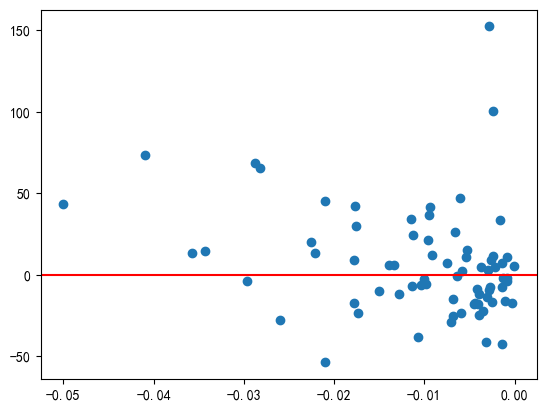

In [34]:
plt.scatter(dt2['macdhist_pre'], dt2['close_next_3_percent_change'])
plt.axhline(y=0, color='r', linestyle='-')

可以看到小于-0.03的时候，普遍涨幅较高，这里要看比值的。

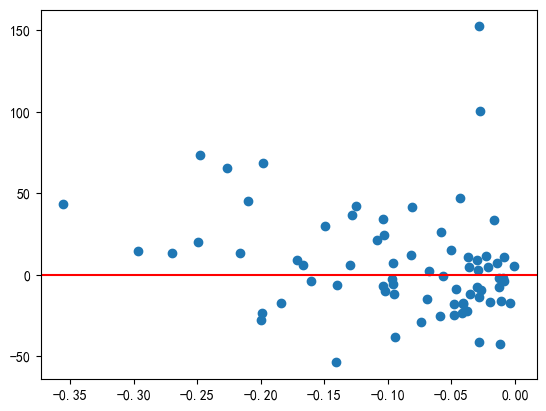

In [35]:
plt.scatter(dt2['macd_close_percent_pre'], dt2['close_next_3_percent_change'])
plt.axhline(y=0, color='r', linestyle='-')

看起来像是低于0.2，涨幅更倾向于上涨。